# Exploration des activations internes — clusterprep

Charge une expérience existante, sélectionne un amas du **test set**, capture les sorties des modules PyTorch et visualise les feature maps et vecteurs. Exécuter depuis un environnement où `clusterprep` est importable. Aucun réentraînement.

In [58]:
from pathlib import Path
import json, math
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from clusterprep.models import build_model
from clusterprep.training import ExperimentConfig, _inputs
from clusterprep.training_core import forward_model
from clusterprep.dataset import ClusterDataset
from torchinfo import summary as torchinfo_summary

# ===== PARAMÈTRES À MODIFIER =====
EXPERIMENT_DIR = Path("/Users/antoinegdrn/PH_Project_I/results/clusterprep_cv/rr_rh/dual_encoder_ssn_rr_rh_cv-cv-20261025T172054-074dee02/final")
CHECKPOINT_PATH = EXPERIMENT_DIR / "best.pt"
CONFIG_PATH = EXPERIMENT_DIR / "config.json"
SPLITS_PATH = EXPERIMENT_DIR / "splits.json"
SAMPLE_INDEX = 0                # Index dans le test set
DATA_ROOT_OVERRIDE = None       # Facultatif : racine de RAW/ et CHANDRA/ si les chemins ont changé
PROCESSED_DIR_OVERRIDE = None   # Facultatif : dossier de cache des données prétraitées
SCATTERING_DIR = "/Users/antoinegdrn/PH_Project_I/processed/scattering"          # Obligatoire si modèle utilisant du scattering précalculé
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
MAX_MAPS = 64
FIGURE_COLUMNS = 4
EXPORT_DIR = EXPERIMENT_DIR / "activation_inspection"
EXPORT_FIGURES = False


## 1. Lecture de la configuration et reconstruction du modèle
`config.json` de clusterprep contient une clé `config`. Le checkpoint contient `model_state_dict` et `class_names`. Les incohérences de poids sont signalées explicitement.

In [59]:
metadata = json.loads(CONFIG_PATH.read_text())
config_dict = metadata.get("config", metadata)
config = ExperimentConfig(**config_dict)
manifest = json.loads(SPLITS_PATH.read_text())
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
state = checkpoint.get("model_state_dict", checkpoint)
class_names = checkpoint.get("class_names", metadata.get("class_names", ["DE", "NDE"]))
num_outputs = len(class_names) if config.task == "de_nde" else 2
model = build_model(config, num_classes=num_outputs)
print(f"Utilisation du masque : {model.use_mask}")
model.load_state_dict(state, strict=True)
model = model.to(DEVICE).eval()
print(f"Modèle : {config.model} | mode : {config.mode} | tâche : {config.task}")
print(f"Device : {DEVICE} | paramètres : {sum(p.numel() for p in model.parameters()):,}")
print(f"Échantillons test : {len(manifest['test'])} | classes checkpoint : {class_names}")


Utilisation du masque : True
Modèle : dual_encoder_ssn | mode : multimodal | tâche : rr_rh
Device : mps | paramètres : 265,786
Échantillons test : 48 | classes checkpoint : ['RR', 'RH']


## 2. Choisir un amas du test set
Les entrées sont reconstruites avec `ClusterDataset(augment=False)` et `_inputs`, exactement comme dans la pipeline de prédiction. Les chemins sont ceux enregistrés dans `splits.json`.

In [60]:
test_keys = manifest["test"]
samples = manifest["samples"]
assert test_keys, "Test set vide"
assert 0 <= SAMPLE_INDEX < len(test_keys)

def relocated(info):
    info = dict(info)
    if DATA_ROOT_OVERRIDE is not None:
        root = Path(DATA_ROOT_OVERRIDE)
        for field in ("raw_path", "chandra_path"):
            if info.get(field):
                old = Path(info[field])
                # Reconstitue la partie du chemin à partir de RAW/ ou CHANDRA/.
                parts = old.parts
                markers = [i for i, p in enumerate(parts) if p in ("RAW", "CHANDRA")]
                if not markers:
                    raise ValueError(f"Impossible de relocaliser {old} : RAW/CHANDRA introuvable")
                info[field] = str(root.joinpath(*parts[markers[-1]:]))
    return info

data_info = {k: relocated(samples[k]) for k in test_keys}
key = test_keys[SAMPLE_INDEX]
print(f"Index={SAMPLE_INDEX} | clé={key} | cluster={data_info[key].get('cluster_id')}")
processed_dir = PROCESSED_DIR_OVERRIDE if PROCESSED_DIR_OVERRIDE is not None else config.processed_dir
# Cache scattering optionnel, requis par certains modèles.
if getattr(model, "uses_precomputed_scattering", False) and SCATTERING_DIR is None:
    raise ValueError("Ce modèle nécessite SCATTERING_DIR : indiquer le dossier des coefficients pré-calculés")
dataset = ClusterDataset(
    data_info=data_info, keys=[key], class_names=class_names,
    mode=config.mode, size=config.size, augment=False, cache=False,
    processed_dir=processed_dir, scattering_dir=SCATTERING_DIR,
    task=config.task, candidate_policy=config.candidate_policy,
    include_targets=True,
)
sample = dataset[0]
batch = {k: v.unsqueeze(0).to(DEVICE) if torch.is_tensor(v) else [v]
         for k, v in sample.items()}
inputs = _inputs(batch, config.mode, model)
print("Entrée :", tuple(inputs[0].shape) if isinstance(inputs, tuple) else tuple(inputs.shape))


Index=0 | clé=PSZ2G139.18+56.37.fits | cluster=PSZ2G139.18+56.37
Entrée : (1, 3, 128, 128)


In [61]:
torchinfo_summary(
    model,
    input_data=inputs,
    col_names=[
        "input_size",
        "output_size",
        "num_params",
        "kernel_size",
        "mult_adds",
    ],
    depth=5,
    verbose=0,
)

Layer (type:depth-idx)                        Input Shape               Output Shape              Param #                   Kernel Shape              Mult-Adds
DualEncoderSSN                                [1, 3, 128, 128]          [1, 2]                    --                        --                        --
├─DualSSNEncoder: 1-1                         [1, 1, 128, 128]          [1, 768]                  --                        --                        --
│    └─Sequential: 2-1                        [1, 1, 128, 128]          [1, 32, 64, 64]           --                        --                        --
│    │    └─Sequential: 3-1                   [1, 1, 128, 128]          [1, 8, 128, 128]          --                        --                        --
│    │    │    └─Conv2d: 4-1                  [1, 1, 128, 128]          [1, 8, 128, 128]          208                       [5, 5]                    3,407,872
│    │    │    └─BatchNorm2d: 4-2             [1, 8, 128, 128]      

## 3. Visualisation des modalités en entrée

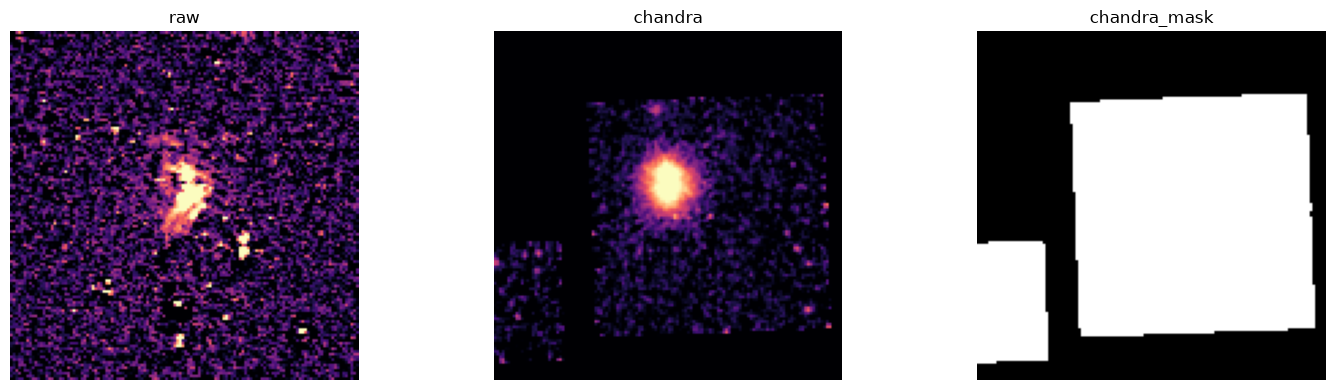

In [28]:
modalities = ["raw"] + (["chandra", "chandra_mask"] if config.mode != "raw" else [])
fig, axs = plt.subplots(1, len(modalities), figsize=(5*len(modalities), 4), squeeze=False)
for ax, name in zip(axs[0], modalities):
    ax.imshow(sample[name].squeeze().numpy(), origin="lower", cmap="magma" if name != "chandra_mask" else "gray")
    ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()


## 4. Capturer les activations
Les **forward hooks** enregistrent la sortie de chaque module feuille appelé pendant le forward (Conv2d, BatchNorm, activations, pooling, Linear, etc.). Les tenseurs sont détachés et transférés sur CPU. Les sorties composites sont également prises en charge. Attention : pour les gros réseaux, la capture peut utiliser beaucoup de mémoire.

In [29]:
def extract_tensors(obj, prefix=""):
    if isinstance(obj, torch.Tensor):
        return {prefix or "output": obj.detach().cpu()}
    if isinstance(obj, (tuple, list)):
        out = {}
        for i, x in enumerate(obj): out.update(extract_tensors(x, f"{prefix}[{i}]"))
        return out
    if isinstance(obj, dict):
        out = {}
        for k, x in obj.items(): out.update(extract_tensors(x, f"{prefix}.{k}"))
        return out
    return {}

activations = {}
handles = []
call_counts = {}
for name, module in model.named_modules():
    if name and not list(module.children()):
        def hook(mod, args, output, layer_name=name):
            count = call_counts.get(layer_name, 0)
            call_counts[layer_name] = count + 1
            activations[f"{layer_name}#{count} ({type(mod).__name__})"] = extract_tensors(output)
        handles.append(module.register_forward_hook(hook))
try:
    with torch.no_grad():
        logits = forward_model(model, inputs)
finally:
    for handle in handles: handle.remove()

print(f"{len(activations)} appels de couches capturés")
for name, outputs in activations.items():
    print(name, " | ", ", ".join(f"{k}: {tuple(t.shape)}" for k,t in outputs.items()))


69 appels de couches capturés
radio_encoder.encoder.0#0 (Conv2d)  |  output: (1, 8, 128, 128)
radio_encoder.encoder.1#0 (BatchNorm2d)  |  output: (1, 8, 128, 128)
radio_encoder.encoder.2#0 (LeakyReLU)  |  output: (1, 8, 128, 128)
radio_encoder.encoder.3#0 (Dropout2d)  |  output: (1, 8, 128, 128)
radio_encoder.encoder.4#0 (Conv2d)  |  output: (1, 16, 128, 128)
radio_encoder.encoder.5#0 (BatchNorm2d)  |  output: (1, 16, 128, 128)
radio_encoder.encoder.6#0 (LeakyReLU)  |  output: (1, 16, 128, 128)
radio_encoder.encoder.7#0 (Dropout2d)  |  output: (1, 16, 128, 128)
radio_encoder.encoder.8#0 (MaxPool2d)  |  output: (1, 16, 64, 64)
radio_encoder.encoder.9#0 (Conv2d)  |  output: (1, 32, 64, 64)
radio_encoder.encoder.10#0 (BatchNorm2d)  |  output: (1, 32, 64, 64)
radio_encoder.encoder.11#0 (LeakyReLU)  |  output: (1, 32, 64, 64)
radio_encoder.encoder.12#0 (Dropout2d)  |  output: (1, 32, 64, 64)
radio_encoder.to_latent.0#0 (Conv2d)  |  output: (1, 32, 32, 32)
radio_encoder.to_latent.1#0 (BatchN

## 5. Probabilités prédites

In [42]:
with torch.no_grad():
    if config.task == "rr_rh":
        probabilities = torch.sigmoid(logits).detach().cpu().flatten().tolist()
        names = ["RR", "RH"]
    else:
        probabilities = torch.softmax(logits, dim=-1).detach().cpu().flatten().tolist()
        names = list(class_names)
for name, p in zip(names, probabilities):
    print(f"P({name}) = {p:.4f}")
print(f"Label réel : {sample['label']}")


P(RR) = 0.4634
P(RH) = 0.7622
Label réel : tensor([0., 1.])


## 6. Visualiser chaque couche
Les sorties 4D `[B,C,H,W]` sont représentées canal par canal ; les sorties 2D `[B,F]` comme des vecteurs ; les autres formes sont aplaties. L’échelle de couleurs est adaptée à chaque canal pour rendre visibles les structures même à faible amplitude.

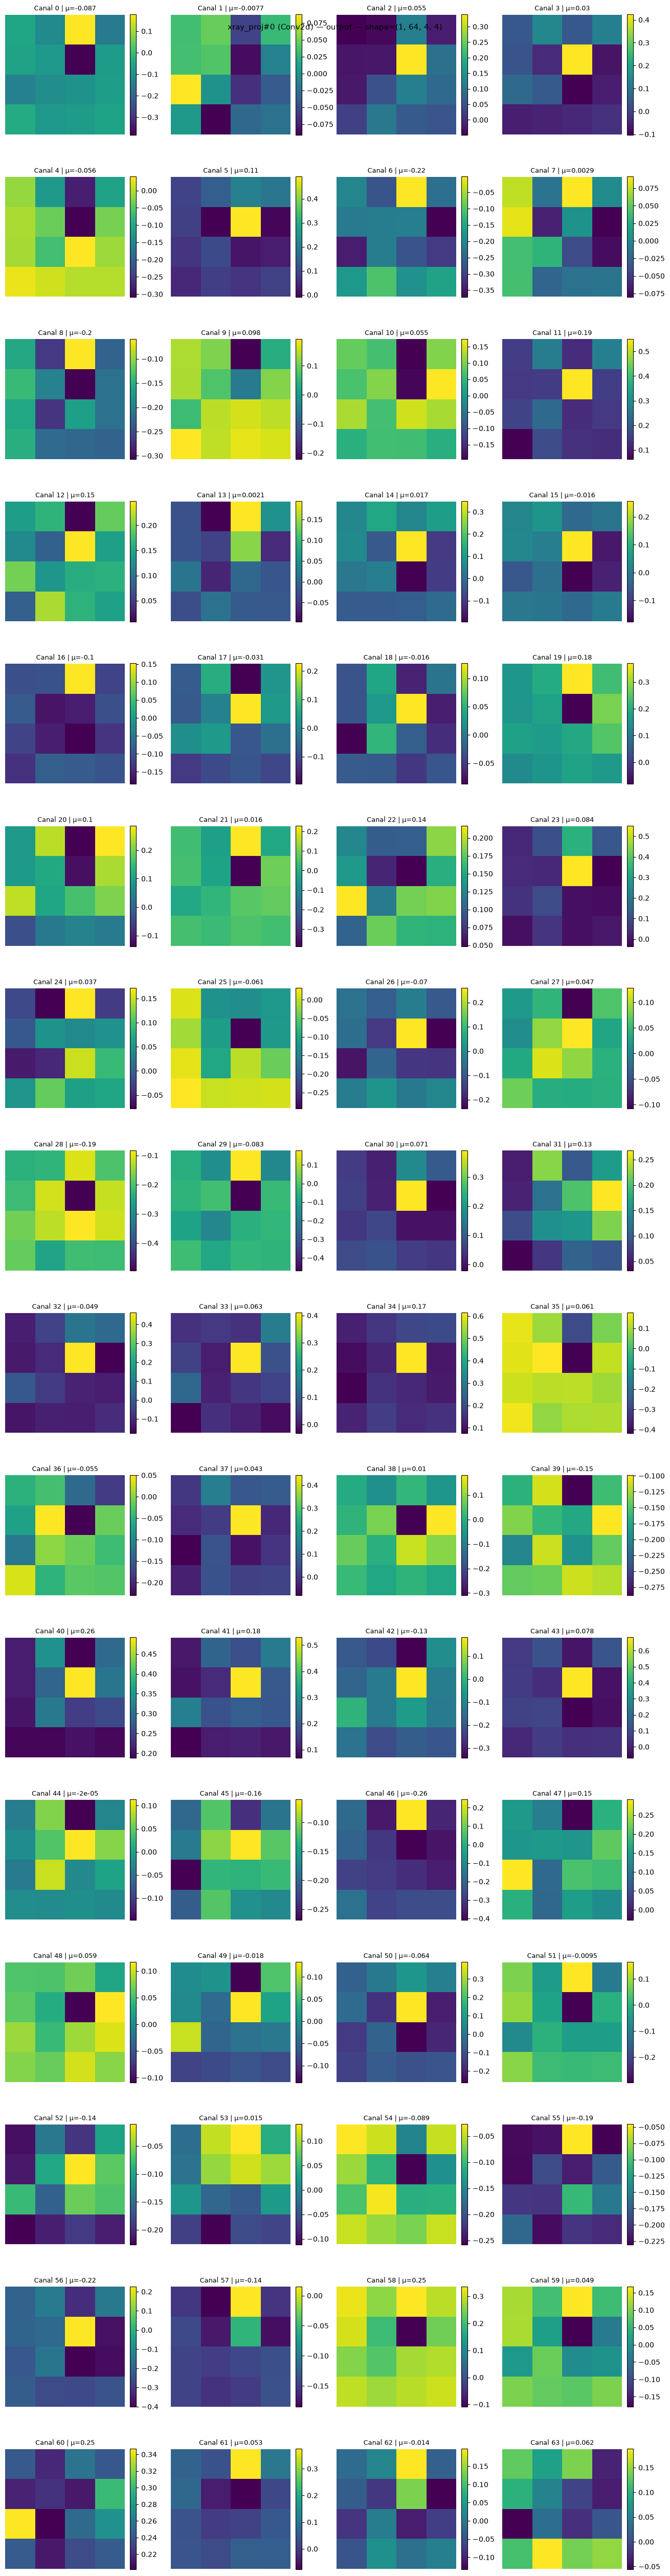

In [46]:
def plot_activation(name, outputs, max_maps=MAX_MAPS, columns=FIGURE_COLUMNS):
    for suffix, tensor in outputs.items():
        a = tensor.float().numpy()
        if a.ndim == 4:
            maps = a[0]
            n = min(len(maps), max_maps)
            if not n: continue
            cols = min(columns, n); rows = math.ceil(n / cols)
            fig, axs = plt.subplots(rows, cols, figsize=(3.3*cols, 3.2*rows), squeeze=False)
            for i, ax in enumerate(axs.flat):
                if i < n:
                    im = ax.imshow(maps[i], origin="lower", cmap="viridis")
                    ax.set_title(f"Canal {i} | μ={maps[i].mean():.2g}", fontsize=9)
                    fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
                ax.axis("off")
        else:
            v = a[0].reshape(-1) if a.ndim >= 2 else a.reshape(-1)
            fig, ax = plt.subplots(figsize=(min(15, max(7, len(v)/12)), 3))
            if len(v) > 2000:
                ax.hist(v, bins=70); ax.set_xlabel("Valeur"); ax.set_ylabel("Effectif")
            else:
                ax.plot(v, lw=1); ax.set_xlabel("Indice de feature"); ax.set_ylabel("Activation")
            axs = None
        fig.suptitle(f"{name} — {suffix} — shape={tuple(tensor.shape)}", fontsize=11)
        fig.tight_layout()
        if EXPORT_FIGURES:
            EXPORT_DIR.mkdir(parents=True, exist_ok=True)
            import re
            filename = re.sub(r"[^a-zA-Z0-9_-]+", "_", f"{name}_{suffix}")[:140]
            fig.savefig(EXPORT_DIR / f"{filename}.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)

# Pour inspecter une couche particulière, remplacer par : SELECTED_LAYERS = ["radio_encoder"]
SELECTED_LAYERS = ["xray_proj#0 (Conv2d)"]  # Liste de sous-chaînes, ou None pour toutes les couches
for name, outputs in activations.items():
    if SELECTED_LAYERS is None or any(s.lower() in name.lower() for s in SELECTED_LAYERS):
        plot_activation(name, outputs)


## 7. Comparer quantitativement les couches
Résumé des activations (moyenne, écart-type, fraction de zéros, amplitude) utile pour détecter des couches saturées ou inactives.

In [8]:
import pandas as pd
rows = []
for layer, outputs in activations.items():
    for suffix, t in outputs.items():
        if not t.is_floating_point(): continue
        v = t.float()
        rows.append(dict(layer=layer, output=suffix, shape=str(tuple(v.shape)),
                         mean=float(v.mean()), std=float(v.std(unbiased=False)),
                         zero_fraction=float((v == 0).float().mean()),
                         min=float(v.min()), max=float(v.max())))
summary = pd.DataFrame(rows)
display(summary)
if EXPORT_FIGURES:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(EXPORT_DIR / "activation_statistics.csv", index=False)


,layer,output,shape,mean,std,zero_fraction,min,max
0,radio_encoder.encoder.0#0 (Conv2d),output,"(1, 8, 128, 128)",-0.042577,0.174109,0.0,-1.868320,1.028488
1,radio_encoder.encoder.1#0 (BatchNorm2d),output,"(1, 8, 128, 128)",-0.102698,0.801499,0.0,-5.226753,4.878726
2,radio_encoder.encoder.2#0 (LeakyReLU),output,"(1, 8, 128, 128)",0.197775,0.512630,0.0,-1.045351,4.878726
3,radio_encoder.encoder.3#0 (Dropout2d),output,"(1, 8, 128, 128)",0.197775,0.512630,0.0,-1.045351,4.878726
4,radio_encoder.encoder.4#0 (Conv2d),output,"(1, 16, 128, 128)",-0.049590,0.369860,0.0,-4.046880,3.492442
...,...,...,...,...,...,...,...,...
64,fusion.4#0 (LeakyReLU),output,"(1, 64, 4, 4)",0.311659,1.077473,0.0,-0.636450,5.941997
65,classifier.0#0 (Linear),output,"(1, 64)",-0.247168,0.716151,0.0,-1.774777,1.227257
66,classifier.1#0 (LeakyReLU),output,"(1, 64)",0.106118,0.403627,0.0,-0.354955,1.227257
67,classifier.2#0 (Dropout),output,"(1, 64)",0.106118,0.403627,0.0,-0.354955,1.227257


### Remarques
- Les couches utilisées plusieurs fois portent des suffixes `#0`, `#1`, etc.
- Les opérations fonctionnelles (`torch.cat`, additions, fonctions `torch.nn.functional` sans module) ne sont pas capturées par les hooks : pour les inspecter, il faut instrumenter le `forward` ou utiliser `torch.fx` quand il est compatible.
- Pour un modèle de scattering, fournir les coefficients précalculés correspondant exactement à l’expérience.
- Les cartes montrent des **activations**, pas des cartes d’attribution (Grad-CAM).
- `splits.json` doit contenir les informations `samples` et des chemins FITS encore valides. Si les données ont été déplacées, définir `DATA_ROOT_OVERRIDE`.